# Домашнее задание 1 по рекомендательным системам

**Томак Андрей Владимирович**  
Осень 2026

Задача — рекомендовать публичные GitHub-репозитории по историческим добавлениям в избранное. Сравниваются пять моделей собственной реализации: ItemKNN, iALS, EASE, FM с метапризнаками и iALS с целевым сигналом давности интереса. Контроли — популярность и FM только с идентификаторами.

Основная метрика **NDCG@10** выбрана до подбора параметров. Дополнительные метрики — Recall@10, Precision@10, HitRate@10 и покрытие каталога. Вся настройка выполняется на validation; test используется после фиксации параметров.

## Запуск и воспроизводимость

Python 3.12; зависимости перечислены в `requirements.txt`. Из корня проекта:

```text
python -m pip install -r requirements.txt
python data_pipeline.py --prepare
python run_experiments.py --force --no-download
python execute_notebook.py
python verify_submission.py --run-tests
```

Ноутбук также можно выполнить через JupyterLab. При первом запуске загрузка данных потоковая; полные исходные архивы на диск не записываются. Уже завершённые эксперименты переиспользуются при совпадении отпечатка исходного кода. Для независимого повторного обучения установите `RECOMPUTE_EXPERIMENTS = True` в следующей ячейке. Случайные зерна фиксированы; FM обучается на CPU.

Данные, отображения идентификаторов и промежуточные матрицы находятся в исключённом из Git каталоге `.cache_data/`. На GitHub публикуются исходный код, агрегаты и выполненный ноутбук.

In [1]:
import os
for key, value in {"OPENBLAS_NUM_THREADS": "1", "MKL_NUM_THREADS": "1", "OMP_NUM_THREADS": "4", "NUMBA_NUM_THREADS": "4"}.items():
    os.environ.setdefault(key, value)
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from data_pipeline import prepare_data, load_data, processed_cache_valid
from run_experiments import run_experiments, SEARCH_SPACES
from reporting import create_eda_figures, create_result_figures
ROOT = Path.cwd()
assert (ROOT / "models").is_dir(), "Запускайте ноутбук из корня проекта"
RECOMPUTE_EXPERIMENTS = False
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_colwidth", None)

## Источник и смысл данных

Источник: [GH Archive](https://www.gharchive.org/), исходные JSON-события публичной ленты GitHub. Самостоятельная выборка использует файлы с **2014-09-01 по 2014-10-08** включительно: 912 часовых архивов, примерно 8.61 ГБ в сжатом виде по сети. Это самостоятельно сформированная выборка исторических событий с собственными правилами отбора и оценки.

`WatchEvent` с `payload.action == "started"` означает добавление репозитория в избранное ([описание события](https://docs.github.com/en/rest/using-the-rest-api/github-event-types#watchevent)). Пользователь — исторический `actor` login; объект — `repository.id`; время — `created_at`. Используются язык `repository.language` и владелец `repository.owner` из исторического снимка. Эти метапризнаки имеют смысл: интерес к языкам и проектам одного владельца может переноситься на другие репозитории.

Релевантным считается репозиторий с новым наблюдаемым добавлением в избранное в следующем периоде. Отсутствие события не считается достоверным негативным отзывом. Рекомендуются только объекты каталога, известного к концу train.

Файлы 2014 года записывались через старый Timeline API. Их имена отражают часы коллектора и не заменяют время события: разбиение использует `created_at` с часовым смещением, приведённое к UTC. Полные ссылки и SHA-256 всех архивов сохранены в `results/source_archives.json`. Код GH Archive имеет MIT-лицензию; архив событий включает сторонние материалы и этой лицензией не покрывается. Исходные данные в репозиторий работы не включены.

In [2]:
if not processed_cache_valid():
    prepare_data(download=True)
data = load_data()
s = data["summary"]
assert all(s["requirements_met"].values())
display(pd.DataFrame([{
    "пользователи": s["n_users"], "репозитории": s["n_items"],
    "взаимодействия": s["n_interactions"],
    "разреженность train": 1 - s["density_train"],
    "категории языка с unknown": s["language_categories_including_unknown"],
    "категории владельца с unknown": s["owner_categories_including_unknown"]
}]))
display(pd.Series(s["raw"], name="Исходные события и пары").to_frame())

,пользователи,репозитории,взаимодействия,разреженность train,категории языка с unknown,категории владельца с unknown
0,46083,2995,386338,0.997376,50,2415


,Исходные события и пары
retained_star_events,1282609
unique_user_item_pairs,1265965
duplicate_star_events,16644
unique_users,260949
unique_items,259736
raw_events,15194184
watch_events,1282614
with_language,1188449
with_owner,1282609
missing_identity_or_time,5


## Очистка и отбор данных

Отбрасываются записи без пользователя, репозитория или корректного времени, непубличные события и явно отмеченные боты. Повторы `(user, item)` объединяются в первое наблюдаемое событие: повторное добавление уже известного объекта не превращается в новую релевантную рекомендацию.

Каталог ограничен 3 000 наиболее частыми объектами **в train**; при равенстве частот используется числовой исторический ID. Затем только на train выполняется итеративная фильтрация: минимум три события на пользователя и пять на объект. Карты пользователей, объектов и категорий после этого фиксируются. Ограничение каталога делает полный EASE и ранжирование всех кандидатов выполнимыми на обычном компьютере; выводы относятся к этому активному сегменту.

Метаданные берутся из последнего снимка, наблюдавшегося **до границы train**. Отсутствующая категория кодируется как 0. Ни текущая популярность GitHub, ни будущие описания, владельцы или языки не используются. Число пропусков, повторов и исключённых пар показывается ниже.

,Обработка исходных архивов
raw_events,15194184
watch_events,1282614
retained_star_events,1282609
with_language,1188449
with_owner,1282609
missing_identity_or_time,5


Пустые исходные часовые архивы: ['2014-09-23-12', '2014-09-30-14']


,raw_unique_pairs,dropped_unknown_item,dropped_unknown_user,kept_pairs
train,1141620,362205,417208,362207
validation,33911,10833,16068,7010
test,90434,30623,42690,17121


,Пропуски метаданных
объекты без языка,141
объекты без владельца,0


,language,n_items,train_interactions
0,JavaScript,928,122738
1,Java,283,29388
2,Objective-C,222,25472
3,CSS,152,24833
4,unknown,141,23581
5,Python,213,23111
6,Ruby,198,18792
7,Go,126,16769
8,C,120,15528
9,PHP,144,11431


,Совместное использование метапризнака
владельцы нескольких объектов,317
объекты с общим владельцем,898


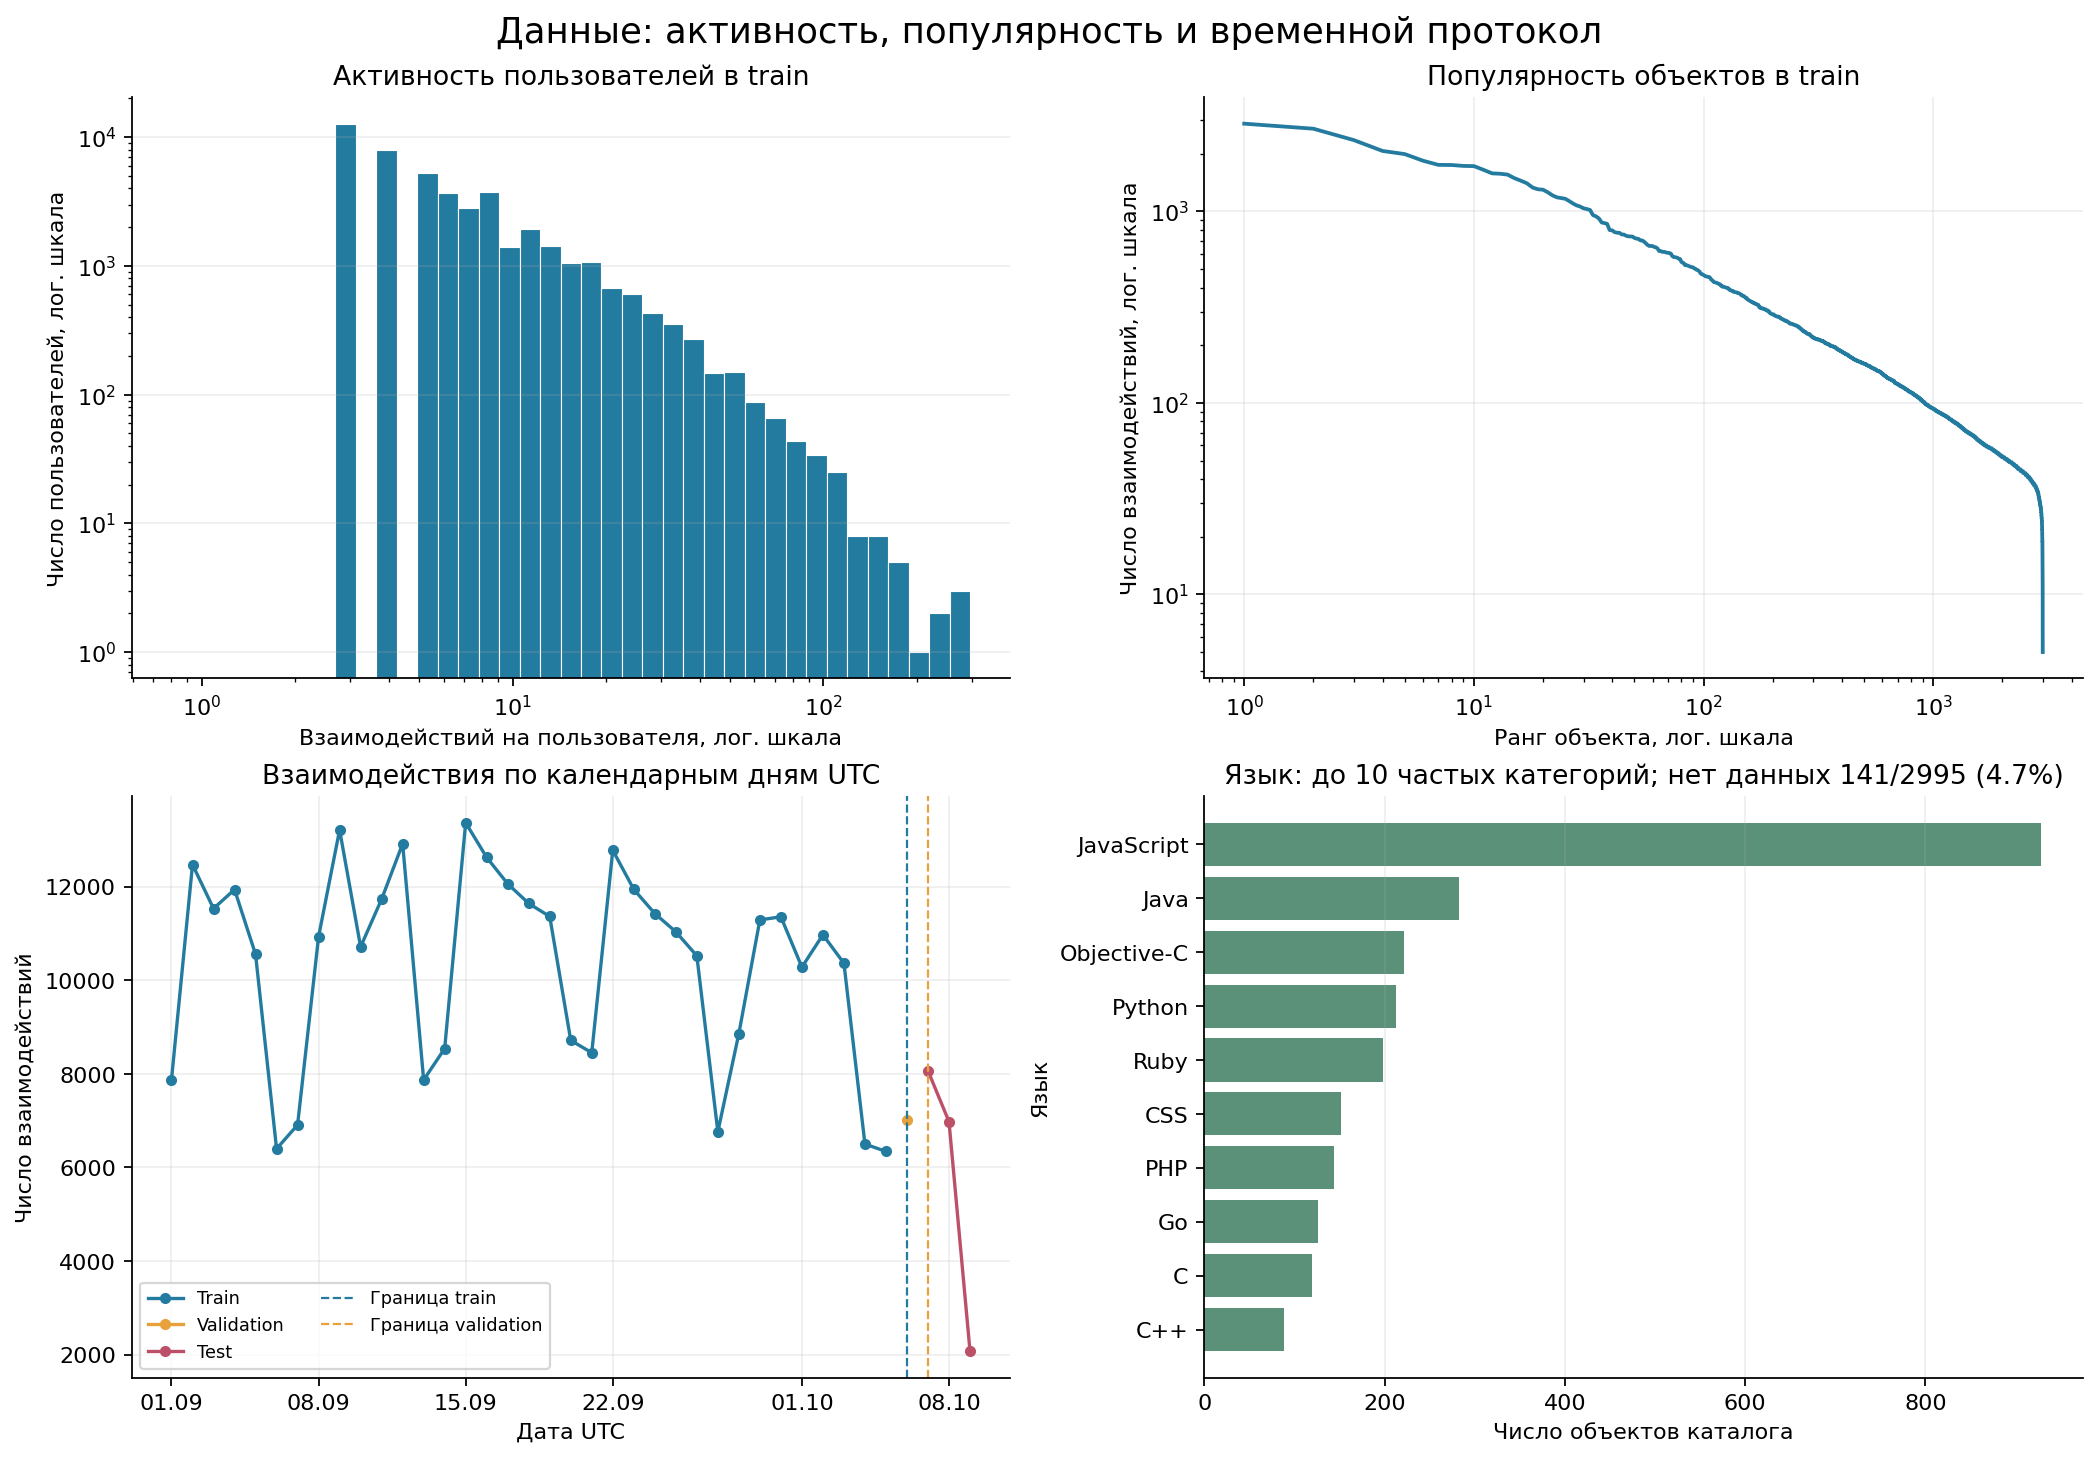

In [3]:
archive_rows = json.loads((ROOT / "results/source_archives.json").read_text(encoding="utf-8")) if (ROOT / "results/source_archives.json").exists() else []
if archive_rows:
    counters = {}
    for row in archive_rows:
        for key, value in row["counts"].items():
            counters[key] = counters.get(key, 0) + value
    display(pd.Series(counters, name="Обработка исходных архивов").to_frame())
if s.get("empty_source_hours"):
    print("Пустые исходные часовые архивы:", s["empty_source_hours"])
display(pd.DataFrame(s["splits"]).T.fillna(0).astype(int))
display(pd.Series({"объекты без языка": s["items_missing_language"], "объекты без владельца": s["items_missing_owner"]}, name="Пропуски метаданных").to_frame())
if s.get("language_distribution"):
    display(pd.DataFrame(s["language_distribution"]).sort_values("train_interactions", ascending=False).head(12))
if "owners_with_multiple_items" in s:
    display(pd.Series({"владельцы нескольких объектов": s["owners_with_multiple_items"], "объекты с общим владельцем": s["items_with_shared_owner"]}, name="Совместное использование метапризнака").to_frame())
for image_path in create_eda_figures(data, ROOT / "figures"):
    display(Image(filename=str(image_path)))

In [4]:
activity = np.diff(data["train"].indptr)
popularity = np.asarray(data["train"].sum(axis=0)).ravel()
top_count = max(1, int(np.ceil(0.01 * s["n_items"])))
top_share = float(np.sort(popularity)[-top_count:].sum() / popularity.sum())
eda_findings = [
    f"Число взаимодействий в обучающей истории: медиана {np.median(activity):.0f}, среднее {activity.mean():.2f}. При коротких историях общие признаки языка и владельца могут помочь оценить новые объекты.",
    f"Разреженность train — {1-s['density_train']:.3%}. На верхний 1% каталога ({top_count} объектов) приходится {top_share:.2%} обучающих событий: популярность следует включить отдельным контролем.",
    f"Язык отсутствует у {s['items_missing_language']} из {s['n_items']} объектов; пропуски сохраняются отдельной категорией. Метапризнаки доступны до момента рекомендации."
]
if s.get("language_distribution"):
    language_frame = pd.DataFrame(s["language_distribution"])
    leading_language = language_frame.sort_values("n_items", ascending=False).iloc[0]
    eda_findings.append(f"Самый частый язык по числу объектов — {leading_language['language']}: {int(leading_language['n_items'])} репозиториев.")
if "items_with_shared_owner" in s:
    eda_findings.append(f"Общий владелец встречается у {s['items_with_shared_owner']} объектов каталога; {s['owners_with_multiple_items']} владельцев имеют несколько объектов. Это позволяет FM переносить информацию между проектами одного владельца; пользу проверяет отдельный контроль без metadata.")
display(Markdown("\n\n".join(eda_findings)))

Число взаимодействий в обучающей истории: медиана 5, среднее 7.86. При коротких историях общие признаки языка и владельца могут помочь оценить новые объекты.

Разреженность train — 99.738%. На верхний 1% каталога (30 объектов) приходится 12.92% обучающих событий: популярность следует включить отдельным контролем.

Язык отсутствует у 141 из 2995 объектов; пропуски сохраняются отдельной категорией. Метапризнаки доступны до момента рекомендации.

Самый частый язык по числу объектов — JavaScript: 928 репозиториев.

Общий владелец встречается у 898 объектов каталога; 317 владельцев имеют несколько объектов. Это позволяет FM переносить информацию между проектами одного владельца; пользу проверяет отдельный контроль без metadata.

## Единый протокол оценки

Глобальное временное разбиение задано в `config/data_config.json` до обучения. Train содержит события строго до своей границы, validation — до следующей границы, test — оставшиеся более поздние события. Точные границы и размеры выводятся из сохранённых данных ниже.

Для validation модели обучаются только на train. После выбора параметров каждая модель заново обучается на train + validation; test не участвует ни в выборе признаков, ни в подборе параметров. Каталог и кодировки остаются зафиксированными по train. Новые пользователи и новые объекты исключаются из этой оценки warm-start; количества исключений приведены в EDA. Исключения считаются последовательно: сначала неизвестный пользователь, затем неизвестный объект среди оставшихся пар.

Набор кандидатов для каждого пользователя — **весь фиксированный каталог**, из которого удалена известная к моменту рекомендации история. Выборка негативных кандидатов при оценке не применяется. Метрики усредняются по всем пользователям с хотя бы одним допустимым релевантным объектом, включая пользователей с нулём попаданий. Этот набор пользователей одинаков для всех моделей внутри соответствующего этапа. Равные score упорядочиваются по фиксированному индексу объекта.

Бинарная релевантность на test одна и та же для всех моделей, включая модель с другим обучающим таргетом.

Для пользователя $u$: $Recall@10=|Top_{10}(u)\cap R_u|/|R_u|$; $DCG@10=\sum_{r=1}^{10}rel_r/\log_2(r+1)$; $NDCG@10=DCG@10/IDCG@10$. NDCG учитывает порядок первых рекомендаций, Recall — долю восстановленных будущих интересов. Precision делится на 10, HitRate показывает наличие хотя бы одного попадания; покрытие — долю объектов каталога, попавших в выдачи.

In [5]:
display(pd.Series({"train до UTC": s["train_cutoff_utc"], "validation до UTC": s["validation_cutoff_utc"], "первое событие UTC": s["event_time_start_utc"], "последнее событие UTC": s["event_time_end_utc"]}).to_frame("время"))
split_table = []
for name in ["train", "validation", "test"]:
    X = data[name]
    split_table.append({"часть": name, "взаимодействия": X.nnz, "активные пользователи": int(np.count_nonzero(np.diff(X.indptr))), "активные объекты": int(np.count_nonzero(np.asarray(X.sum(axis=0))))})
display(pd.DataFrame(split_table))
assert data["train"].multiply(data["validation"]).nnz == 0
assert (data["train"] + data["validation"]).multiply(data["test"]).nnz == 0
assert data["train_timestamps"].data.max() < pd.Timestamp(s["train_cutoff_utc"]).timestamp()
assert data["validation_timestamps"].data.min() >= pd.Timestamp(s["train_cutoff_utc"]).timestamp()
assert data["test_timestamps"].data.min() >= pd.Timestamp(s["validation_cutoff_utc"]).timestamp()

,время
train до UTC,2014-10-06T00:00:00Z
validation до UTC,2014-10-07T00:00:00Z
первое событие UTC,2014-09-01T07:05:35Z
последнее событие UTC,2014-10-09T07:05:30Z


,часть,взаимодействия,активные пользователи,активные объекты
0,train,362207,46083,2995
1,validation,7010,4615,1827
2,test,17121,9867,2514


## Модели собственной реализации

### ItemKNN

Используется item-based CF. Сходство столбцов истории $x_i,x_j$: $w_{ij}=x_i^Tx_j/(\|x_i\|\|x_j\|+s)$ при $i\ne j$. Для каждого целевого объекта сохраняются только $k$ соседей; диагональ обнуляется. Оценки пользователя: $\hat r_u=x_uW$. При $s=0$ получаем косинусное сходство.

### iALS

Для бинарной истории $r_{ui}$: $p_{ui}=1[r_{ui}>0]$, $c_{ui}=1+\alpha r_{ui}$. Минимизируется $\sum_{ui}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\sum_u\|x_u\|^2+\sum_i\|y_i\|^2)$. Факторы поочерёдно пересчитываются из собственных нормальных уравнений. Неизвестные пары входят в функцию потерь с $p=0,c=1$; SciPy/NumPy используются только для матричных операций, Numba — для ускорения циклов.

### EASE

Минимизируется $\|X-XB\|_F^2+\lambda\|B\|_F^2$, $diag(B)=0$. При $P=(X^TX+\lambda I)^{-1}$ коэффициенты $B_{ij}=-P_{ij}/P_{jj}$ для $i\ne j$, $B_{jj}=0$. Решение получено через разложение Холецкого; отрицательные коэффициенты разрешены. Рекомендации ранжируются по $x_uB$.

### Factorization Machine

Для one-hot признаков пользователя, репозитория, языка и владельца: $\hat z=w_0+\sum_jw_jz_j+\sum_{j<l}\langle v_j,v_l\rangle z_jz_l$. Взаимодействия вычисляются через сумму квадратов за $O(k\cdot nnz(z))$. Реализация использует Embedding, autograd и Adam из PyTorch; готовая рекомендательная модель не применяется.

Для пользователя, репозитория, языка и владельца выделены непересекающиеся диапазоны индексов признаков. Одинаковые категории одного поля используют общий вектор; пропуск языка или владельца — отдельная обучаемая категория соответствующего поля. L2 применяется к линейным весам и векторам факторов, общий свободный член не регуляризуется.

Обучение — binary cross-entropy и L2. На каждый положительный пример выбираются три равномерных отрицательных объекта с возвращением; все известные положительные пары этого пользователя из текущей обучающей истории исключены. Будущие validation/test-пары при выборе негативов не просматриваются. Score — логит, его порядок совпадает с порядком sigmoid. Контроль FM IDs only использует те же выбранные параметры и обучение, но без языка и владельца.

### iALS с целевым сигналом давности

Пятый метод использует тот же ALS-оптимизатор и те же confidence $c_{ui}=1+\alpha r_{ui}$, но отдельный целевой сигнал:

$$p^{rec}_{ui}=\begin{cases}q+(1-q)\,2^{-(T-t_{ui})/(86400h)},&r_{ui}>0,\\0,&r_{ui}=0.\end{cases}$$

$T$ — граница доступной обучающей истории, $t_{ui}$ — время известного добавления в избранное, $h$ — период полураспада в днях, $q$ — нижняя граница положительного интереса. Гипотеза: недавние предпочтения лучше отражают текущую задачу пользователя; давние интересы сохраняются с ненулевым весом $q$.

Это изменение **таргета**, а не только confidence: в нормальных уравнениях матрица $A=Y^TC_uY+\lambda I$ остаётся прежней, а правая часть $b=Y^TC_up_u$ меняется. Основные параметры ALS берутся у выбранного базового iALS; только $h\in\{0.5,2,7\}$ и $q\in\{0.25,0.75\}$ выбираются по validation. Для итогового refit время $T$ переносится к границе validation. На test по-прежнему оценивается обычное бинарное будущее добавление в избранное.

Нормальные уравнения и формула half-life проверены независимыми малыми примерами в тестах.

## Подбор гиперпараметров на validation

Основная метрика — NDCG@10. Области поиска конечны и заданы в `run_experiments.py`: ItemKNN — 6 конфигураций, iALS — 4, EASE — 3, FM — 4, recency iALS — 6. При равенстве NDCG выбирается первая конфигурация в заранее заданном порядке. Архитектура iALS и confidence удерживаются одинаковыми в сравнении с кастомным сигналом; FM без metadata — контроль с параметрами выбранной FM.

Небольшой бюджет поиска является ограничением эксперимента. Test не используется для расширения сеток или выбора числа эпох. Звёздочками на графике подбора отмечены выбранные конфигурации.

In [6]:
results = run_experiments(force=RECOMPUTE_EXPERIMENTS, download=True)
validation = pd.read_csv(ROOT / "results/validation_trials.csv")
selection = json.loads((ROOT / "results/selected_parameters.json").read_text(encoding="utf-8"))
assert selection["test_not_used_for_selection"]
for name, configurations in selection["search_spaces"].items():
    display(Markdown(f"**Область поиска: {name}**"))
    grid = pd.DataFrame(configurations)
    grid.index = pd.RangeIndex(1, len(grid) + 1, name="Вариант")
    display(grid)
display(Markdown("**Результаты на validation**"))
display(validation[["model", "trial", "ndcg_at_10", "recall_at_10", "fit_seconds"]])
display(Markdown("**Выбранные параметры**"))
selected_table = pd.DataFrame([{
    "Модель": name,
    "Параметры": "; ".join(f"{key} = {value}" for key, value in params.items()) or "Без параметров"
} for name, params in selection["selected"].items()])
display(selected_table.style.set_properties(**{"white-space": "normal", "text-align": "left", "max-width": "640px"}).hide(axis="index"))

Using completed experiments with matching source-code fingerprint.


**Область поиска: ItemKNN**

,k,shrinkage
Вариант,,
1,25,0.0
2,25,10.0
3,75,0.0
4,75,10.0
5,150,0.0
6,150,10.0


**Область поиска: iALS**

,n_factors,alpha,l2,n_iterations
Вариант,,,,
1,16,10.0,1.0,12
2,16,40.0,10.0,12
3,32,10.0,1.0,12
4,32,40.0,10.0,12


...

,n_factors,alpha,l2,n_iterations,half_life_days,floor
Вариант,,,,,,
1,16,40.0,10.0,12,0.5,0.25
2,16,40.0,10.0,12,0.5,0.75
3,16,40.0,10.0,12,2.0,0.25
4,16,40.0,10.0,12,2.0,0.75
5,16,40.0,10.0,12,7.0,0.25
6,16,40.0,10.0,12,7.0,0.75


**Результаты на validation**

,model,trial,ndcg_at_10,recall_at_10,fit_seconds
0,ItemKNN,1,0.041182,0.079491,0.214911
1,ItemKNN,2,0.041428,0.080112,0.204113
2,ItemKNN,3,0.042272,0.082238,0.212937
3,ItemKNN,4,0.042718,0.083202,0.209603
4,ItemKNN,5,0.042638,0.082643,0.221299
5,ItemKNN,6,0.042370,0.082879,0.218715
6,iALS,1,0.045843,0.085400,0.519434
7,iALS,2,0.047245,0.090958,0.489263
8,iALS,3,0.045751,0.081734,1.515466
9,iALS,4,0.041707,0.075531,1.610284


**Выбранные параметры**

Модель,Параметры
ItemKNN,k = 75; shrinkage = 10.0
iALS,n_factors = 16; alpha = 40.0; l2 = 10.0; n_iterations = 12
EASE,l2 = 500.0
FM metadata,n_factors = 32; learning_rate = 0.03; l2 = 0.0001; epochs = 12; batch_size = 2048; negative_ratio = 3
Recency iALS,n_factors = 16; alpha = 40.0; l2 = 10.0; n_iterations = 12; half_life_days = 2.0; floor = 0.25
FM IDs only,n_factors = 32; learning_rate = 0.03; l2 = 0.0001; epochs = 12; batch_size = 2048; negative_ratio = 3
Popularity,Без параметров


## Итоговое сравнение на test

Каждая финальная модель заново обучена на train + validation. Таблица включает пять требуемых методов, неперсональную популярность и контроль FM без метаданных. Время обучения не включает первичную компиляцию Numba; одинаковый score/masking/evaluation используется для всех методов.

,model,role,ndcg_at_10,recall_at_10,precision_at_10,hit_rate_at_10,catalog_coverage_at_10,n_users,fit_seconds
0,Recency iALS,required,0.081105,0.126402,0.020695,0.180805,0.188982,9867,0.534454
1,Popularity,baseline,0.064138,0.144782,0.020827,0.199959,0.013022,9867,0.000608
2,FM IDs only,ablation,0.061541,0.145036,0.020827,0.198237,0.013356,9867,85.698495
3,EASE,required,0.056853,0.102885,0.016885,0.153238,0.505843,9867,1.219697
4,ItemKNN,required,0.052118,0.097427,0.016195,0.142698,0.838731,9867,0.214797
5,iALS,required,0.048872,0.090580,0.014229,0.131144,0.233723,9867,0.479788
6,FM metadata,required,0.022073,0.034333,0.006456,0.060099,0.027045,9867,95.000855


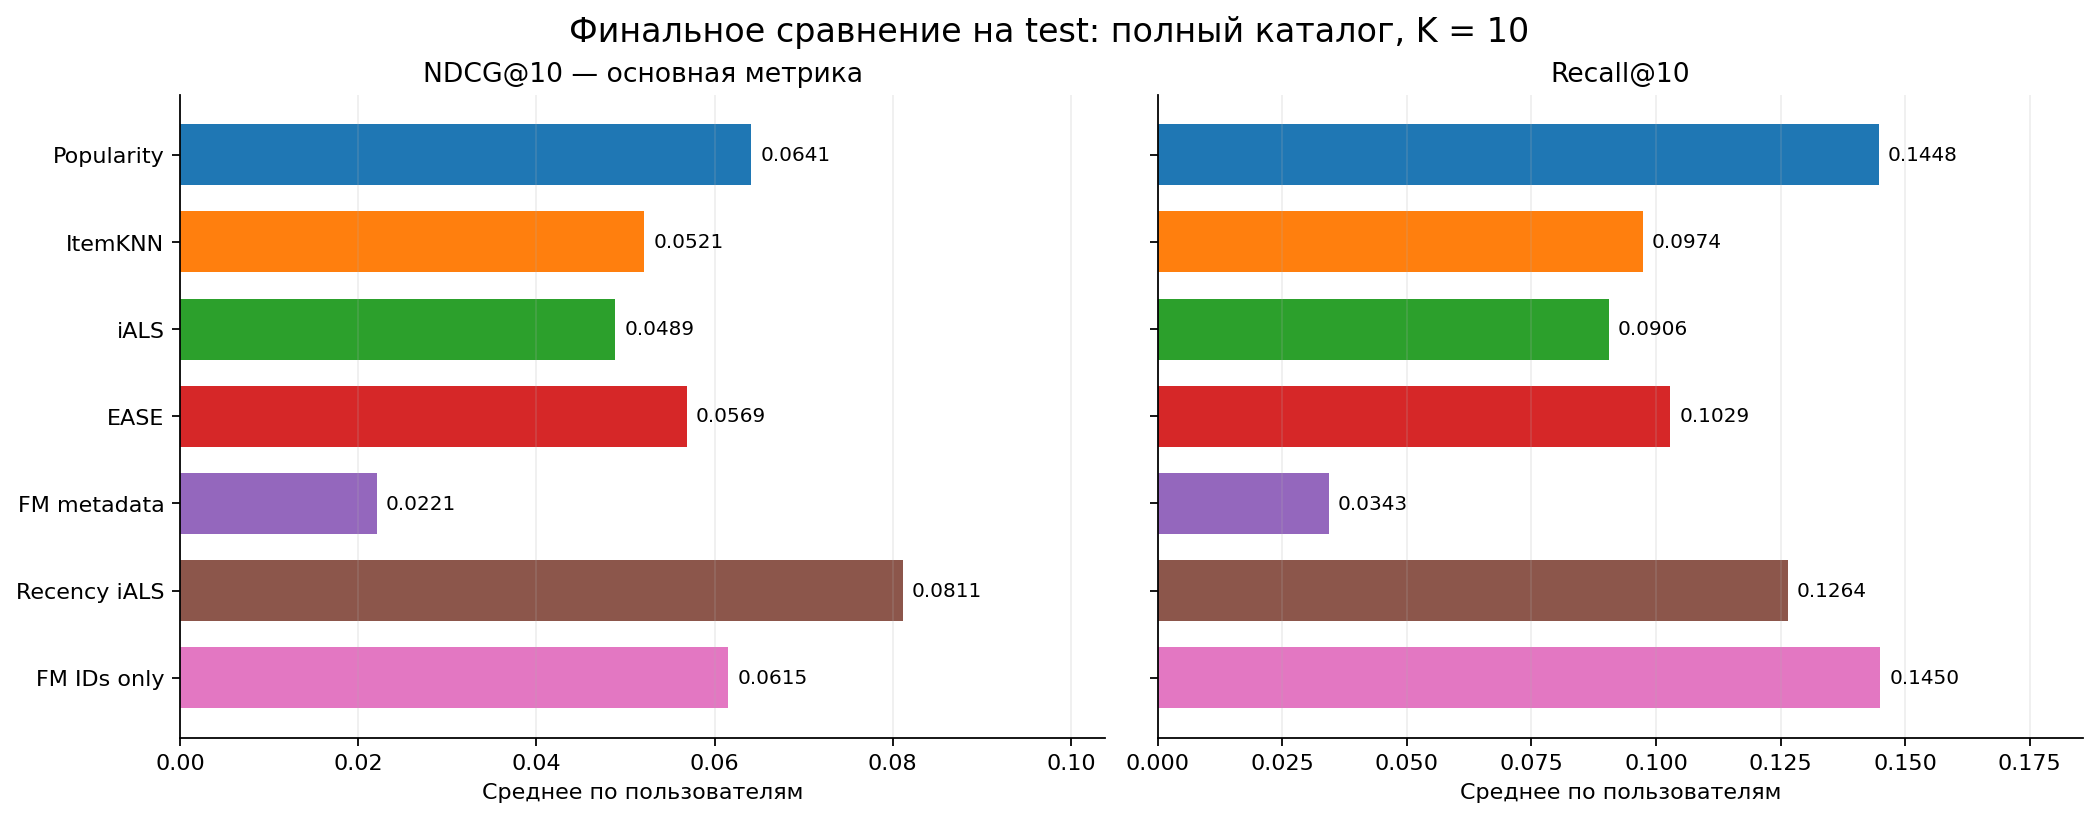

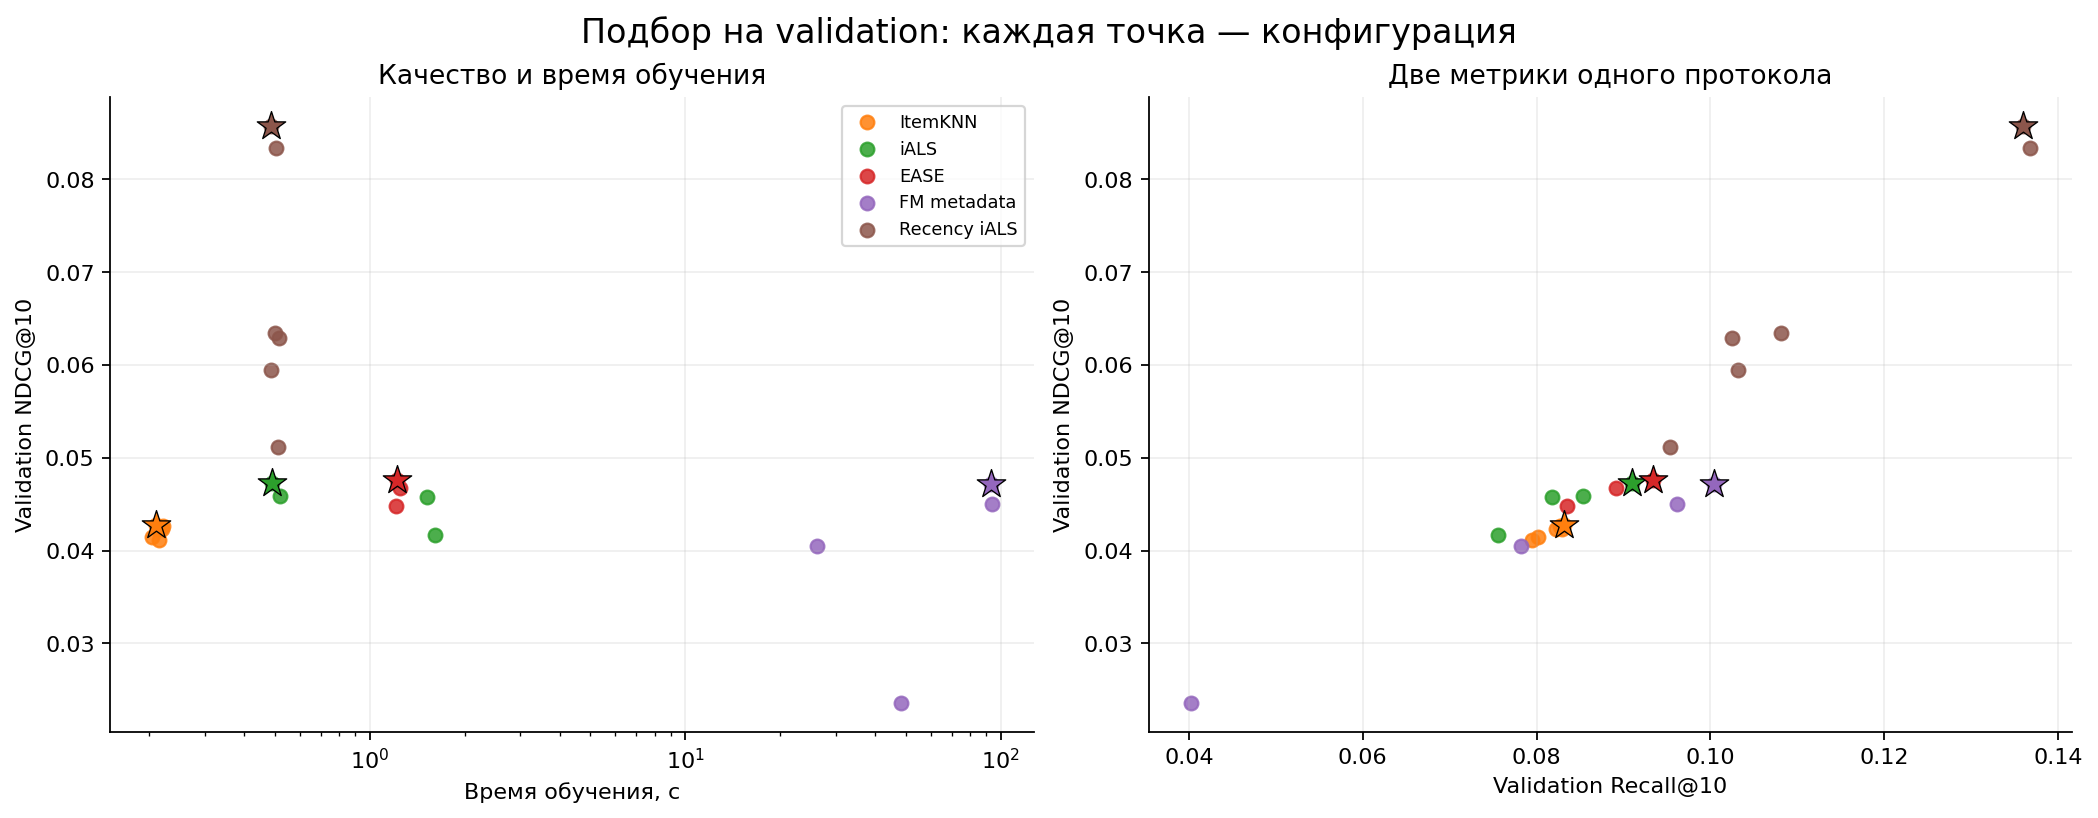

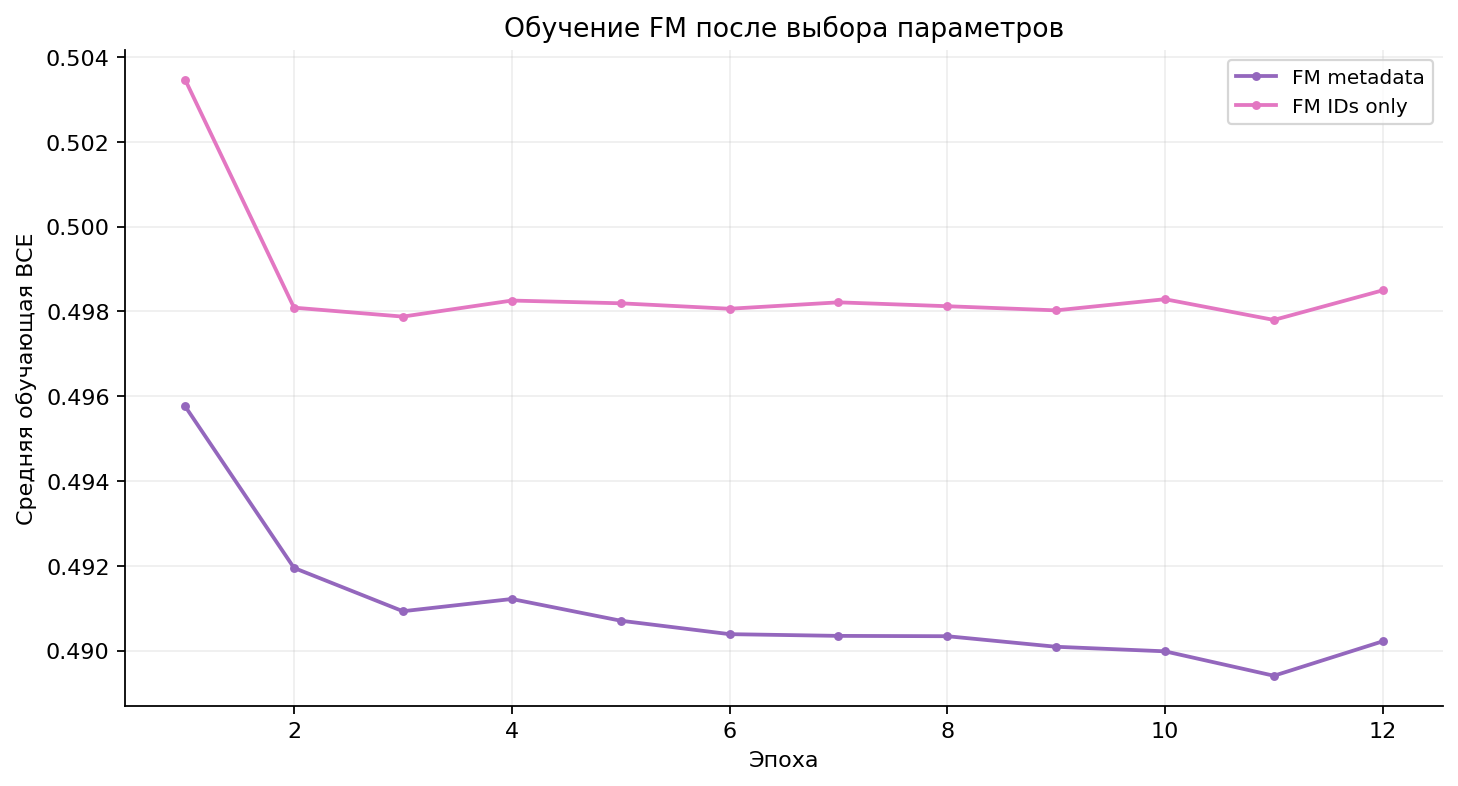

In [7]:
display(results[["model", "role", "ndcg_at_10", "recall_at_10", "precision_at_10", "hit_rate_at_10", "catalog_coverage_at_10", "n_users", "fit_seconds"]].sort_values("ndcg_at_10", ascending=False).reset_index(drop=True))
for image_path in create_result_figures(ROOT / "results", ROOT / "figures"):
    display(Image(filename=str(image_path)))

## Метаданные и кастомный сигнал

Для обеих пар приведён парный bootstrap по тем же пользователям: 1 000 повторных выборок, percentile 95% интервал для разности NDCG@10. Положительная разность означает преимущество первой модели. Это неопределённость по пользователям в одном временном разбиении; она не учитывает перенос на другие периоды и случайные зерна.

In [8]:
d = json.loads((ROOT / "results/evaluation_details.json").read_text(encoding="utf-8"))
display(pd.DataFrame([
    {"сравнение": "FM metadata минус FM IDs only", **d["metadata_ablation"]},
    {"сравнение": "Recency iALS минус iALS", **d["recency_ablation"]}
]))
required = results[results["role"] == "required"].sort_values("ndcg_at_10", ascending=False)
winner = required.iloc[0]
overall = results.sort_values("ndcg_at_10", ascending=False).iloc[0]
sentences = [f"Лучший NDCG@10 среди всех сравниваемых методов у **{overall['model']}**: {overall['ndcg_at_10']:.5f}; Recall@10 = {overall['recall_at_10']:.5f}."]
if overall["model"] != winner["model"]:
    sentences.append(f"Среди пяти основных моделей лучший NDCG@10 у **{winner['model']}**: {winner['ndcg_at_10']:.5f}.")
sentences.append("Параметры лучшей основной модели, выбранные на validation: `" + json.dumps(selection["selected"][winner["model"]], ensure_ascii=False) + "`.")
recall_leader = results.sort_values("recall_at_10", ascending=False).iloc[0]
sentences.append(f"По Recall@10 лидирует **{recall_leader['model']}** ({recall_leader['recall_at_10']:.5f}). Выбор по основной метрике NDCG отражает приоритет порядка первых рекомендаций; он не обеспечивает максимум всех дополнительных метрик.")
for title, key in [("Метапризнаки FM", "metadata_ablation"), ("Сигнал давности", "recency_ablation")]:
    value = d[key]
    uncertainty = "Интервал включает ноль, поэтому преимущество по этому сравнению неустойчиво." if value["ci_low"] <= 0 <= value["ci_high"] else "Интервал не включает ноль в рамках данного временного разбиения."
    sentences.append(f"{title}: изменение среднего NDCG@10 = {value['mean_delta']:+.5f}; 95% интервал разности [{value['ci_low']:+.5f}, {value['ci_high']:+.5f}]. {uncertainty}")
display(Markdown("\n\n".join(sentences)))

,сравнение,mean_delta,ci_low,ci_high
0,FM metadata минус FM IDs only,-0.039468,-0.041745,-0.037075
1,Recency iALS минус iALS,0.032233,0.028055,0.036372


Лучший NDCG@10 среди всех сравниваемых методов у **Recency iALS**: 0.08110; Recall@10 = 0.12640.

Параметры лучшей основной модели, выбранные на validation: `{"n_factors": 16, "alpha": 40.0, "l2": 10.0, "n_iterations": 12, "half_life_days": 2.0, "floor": 0.25}`.

По Recall@10 лидирует **FM IDs only** (0.14504). Выбор по основной метрике NDCG отражает приоритет порядка первых рекомендаций; он не обеспечивает максимум всех дополнительных метрик.

Метапризнаки FM: изменение среднего NDCG@10 = -0.03947; 95% интервал разности [-0.04175, -0.03708]. Интервал не включает ноль в рамках данного временного разбиения.

Сигнал давности: изменение среднего NDCG@10 = +0.03223; 95% интервал разности [+0.02806, +0.03637]. Интервал не включает ноль в рамках данного временного разбиения.

У FM меньшая обучающая BCE сама по себе не означает лучший top-K. Добавление метапризнаков в выбранной конфигурации не дало улучшения на test; это результат контрольного сравнения при одинаковых настройках, а не доказательство бесполезности метаданных вообще. Разные горизонты и наборы пользователей validation/test, редкие категории владельцев и чувствительность обучения ограничивают перенос вывода. Параметры после просмотра test не изменялись.

## Ограничения и проверка

- Источник — наблюдаемая публичная лента, а не полная история интересов или лог показов. Ненаблюдаемая пара не доказывает отсутствие интереса; повторные звёзды и явные боты обработаны, но не все автоматические аккаунты идентифицируются.
- Отбор активных пользователей и популярных объектов по train ограничивает обобщение; новые пользователи и объекты не включены в warm-start метрики. Полный каталог оценки — весь выбранный каталог, а не весь GitHub.
- Старый API содержит login вместо стабильного числового ID пользователя; переименования могут разделять одну историю на несколько идентификаторов.
- Метаданные исторические и зафиксированы по train. Owner у многих объектов почти уникален; его польза проверяется сравнением с FM без метаданных.
- Выводы основаны на одном временном разбиении, одном seed и ограниченном поиске. Изменение сигналов не считается улучшением без соответствующего результата на отложенных данных.

Тесты проверяют нормальные уравнения ALS и EASE, формулу FM, выбор отрицательных примеров, метрики, маскирование истории, временные границы и подготовку данных.

In [9]:
import re, subprocess, sys
tests = subprocess.run([sys.executable, "-B", "-m", "unittest", "discover", "-s", "tests", "-v"], cwd=ROOT, text=True, capture_output=True)
if tests.returncode != 0:
    print(tests.stdout)
    print(tests.stderr)
assert tests.returncode == 0
test_summary = re.search(r"Ran (\d+) tests? in ([\d.]+)s", tests.stderr)
print(f"Все {test_summary.group(1)} теста прошли; время {test_summary.group(2)} с." if test_summary else "Все тесты прошли.")
display(pd.Series(json.loads((ROOT / "results/run_manifest.json").read_text(encoding="utf-8")))[["completed", "python", "fm_device", "threads", "primary_metric"]].to_frame("значение"))

Все 33 теста прошли; время 2.054 с.


,значение
completed,True
python,3.12.10
fm_device,cpu
threads,4
primary_metric,ndcg_at_10


## Источники алгоритмов

- [Hu, Koren, Volinsky, Collaborative Filtering for Implicit Feedback Datasets, 2008](https://yifanhu.net/PUB/cf.pdf).
- [Steck, Embarrassingly Shallow Autoencoders for Sparse Data, 2019](https://arxiv.org/abs/1905.03375).
- [Rendle, Factorization Machines, 2010](https://jame-zhang.github.io/assets/algo/Factorization-Machines-Rendle2010.pdf).
- [GH Archive и происхождение часовых файлов](https://www.gharchive.org/).

Код обучения, предсказаний и формирования рекомендаций написан в `models/`; готовые рекомендательные модели из библиотек не используются.